# Optimal Solar Farm Siting & Capacity Allocation Across India
**Optimization course project: mathematical formulation, solution and analysis**

We have monthly NASA POWER weather and irradiance data for 960 grid cells (2020-2025). The decision is **which cells get a solar plant and how many GW to install there**, subject to a fixed capital budget, so that the energy produced is as large as possible.

We solve two versions of the same problem on the same data:

| | **Easy problem** | **Hard problem** |
|---|---|---|
| Type | Linear program (LP), convex | **Mixed-integer quadratic program (MIQP)**, convex objective + binary decisions |
| Yield | One constant performance ratio for every site | Site-specific heat and wind de-rating |
| Costs | Linear cost per GW | Linear cost per GW **plus a fixed grid-connection charge per plant** |
| Plant size | Any amount from 0 to the cap | Either 0 or between a minimum size and the cap |
| Risk | Ignored | **Penalises the variance of monthly generation** (a mean-variance portfolio of sites) |

The notebook follows the order the course asks for: data, formulation, solution with verification, comparison ("price of realism"), and trade-off analysis.

**Contents**
1. Setup and assumptions
2. Data and the India filter
3. Yield model (easy vs hard)
4. Easy problem (LP)
5. Hard problem (MIQP) and verification
6. Easy vs hard: the price of realism
7. Sensitivity analysis (budget, risk aversion, fixed cost)
8. Additional analysis: regions, seasonality, years, cross-evaluation
9. Summary and caveats

## 1. Setup and assumptions
Everything is self-contained. If a package is missing, run the commented line once.

**Units used throughout:** capacity $x$ in **GW**, energy in **GWh**, money in **Rs crore** (1 crore = 10 million). One GW of PV in a month delivers $\text{GHI}\,[\text{kWh/m}^2/\text{day}] \times \text{days} \times \text{PR}$ GWh, so the units work out without conversion factors.

**The cost and size parameters below are our modelling assumptions, not dataset values.** They set the scale of the problem. The sensitivity section (7) shows how the conclusions move when they change. Cite a source for them in the final report, or state clearly that they are assumptions.

In [2]:
# !pip install shapely pyscipopt cvxpy matplotlib pandas scipy     # run once if imports fail
import os, json, time, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from shapely.geometry import shape, Point

# ---------------- file locations ----------------
CSV_CANDIDATES = ["solar_dataset.csv",
                  "dataset/solar_dataset.csv"]
DATA_CSV = next(p for p in CSV_CANDIDATES if os.path.exists(p))
BOUNDARY = "boundaries/ne_50m_admin_0_countries.geojson"      # Natural Earth country borders; downloaded if absent
BOUNDARY_URL = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_50m_admin_0_countries.geojson"
os.makedirs("figures", exist_ok=True)

MONTHS = ["JAN","FEB","MAR","APR","MAY","JUN","JUL","AUG","SEP","OCT","NOV","DEC"]
DAYS = np.array([31, 28.25, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])

# ---------------- physical assumptions ----------------
ETA0      = 0.85      # non-thermal system efficiency: soiling, inverter, wiring, mismatch, availability
GAMMA     = -0.0040   # c-Si power temperature coefficient [per degC]
U0, U1    = 25.0, 6.84  # Faiman cell-temperature model constants
SUN_HOURS = 8.0       # turns daily GHI (kWh/m2/day) into a production-weighted irradiance in W/m2

# ---------------- economic / design assumptions ----------------
C0     = 4500.0       # variable capex, Rs crore per GW  (= Rs 4.5 crore per MW)
BUDGET = 100_000.0    # total capital budget, Rs crore    (= Rs 1 lakh crore)
UCAP   = 1.0          # per-site capacity cap, GW         (land / grid-cell limit)
FIXED  = 600.0        # fixed grid-connection cost per plant, Rs crore   (hard model only)
LMIN   = 0.2          # minimum viable plant size, GW                     (hard model only)
LAM    = 0.03         # risk aversion: GWh of annual energy given up per GWh^2 of monthly-generation variance

# same palette as the slides
NAVY, GOLD, TEAL, BLUE, GREY = "#0A2340", "#F5A623", "#0E7C86", "#16406B", "#9FB0C7"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#5B6472", "axes.labelcolor": "#2C2C2C", "font.size": 10})
print("data file:", DATA_CSV)

data file: dataset/solar_dataset.csv


## 2. Data and the India filter
The CSV has 960 grid cells × 72 months. The cells form a **rectangular box** (6.5°-37.5°N, 68.5°-97.5°E). That box contains Tibet, Pakistan, Nepal, Bangladesh, Myanmar and a lot of ocean, and the highest-irradiance cells in it are on the Tibetan plateau. An optimiser that sees all 960 cells would put solar farms in China.

We therefore keep only the cells whose **centre lies inside India's border** (Natural Earth 50 m country polygon). This is a judgement call and the only place the data is changed. Everything else comes straight from the CSV.

(69120, 13) | missing values: 0


,min,mean,max
LAT,6.50,22.00,37.50
LON,68.50,83.00,97.50
YEAR,2020.00,2022.50,2025.00
GHI,1.43,5.03,8.77
DNI,0.18,3.91,10.87
DHI,0.48,2.25,4.61
CLEARSKY_GHI,2.70,6.32,9.61
TEMPERATURE,-28.11,19.75,39.97
WIND_SPEED,0.61,3.99,11.36
RELATIVE_HUMIDITY,10.59,66.30,95.41



960 grid cells in the file, 274 of them have their centre inside India -> candidate set I = {1..274}


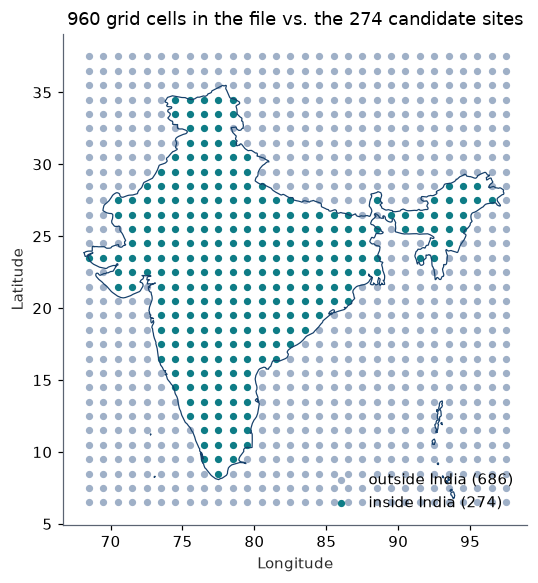

In [4]:
raw = pd.read_csv(DATA_CSV)
raw["m"] = raw.MONTH.map({m: i for i, m in enumerate(MONTHS)})
raw = raw.sort_values(["LAT", "LON", "YEAR", "m"]).reset_index(drop=True)
print(raw.shape, "| missing values:", int(raw.isna().sum().sum()))
display(raw.describe().T[["min", "mean", "max"]].round(2))

if not os.path.exists(BOUNDARY):
    urllib.request.urlretrieve(BOUNDARY_URL, BOUNDARY)
with open(BOUNDARY, "r", encoding="utf-8") as f:
    boundary_data = json.load(f)

feat = [
    f for f in boundary_data["features"]
    if f["properties"].get("ADMIN") == "India"
][0]
india = shape(feat["geometry"])

cells = raw[["LAT", "LON"]].drop_duplicates().reset_index(drop=True)
cells["in_india"] = [india.contains(Point(lo, la)) for la, lo in zip(cells.LAT, cells.LON)]
sites = cells[cells.in_india][["LAT", "LON"]].reset_index(drop=True)
n = len(sites)
print(f"\n{len(cells)} grid cells in the file, {n} of them have their centre inside India -> candidate set I = {{1..{n}}}")

keep_idx = pd.MultiIndex.from_frame(sites)
d = raw[raw.set_index(["LAT", "LON"]).index.isin(keep_idx)].reset_index(drop=True)
assert len(d) == n * 72
arr = lambda c: d[c].to_numpy().reshape(n, 72)       # rows = sites, columns = 72 months (year-major)
GHI, TEMP, WIND = arr("GHI"), arr("TEMPERATURE"), arr("WIND_SPEED")

def draw_india(ax, lw=0.8):
    for g in (india.geoms if india.geom_type == "MultiPolygon" else [india]):
        ax.plot(*g.exterior.xy, color=BLUE, lw=lw)

fig, ax = plt.subplots(figsize=(5.6, 5.4))
out = cells[~cells.in_india]
ax.scatter(out.LON, out.LAT, s=14, c=GREY, label=f"outside India ({len(out)})")
ax.scatter(sites.LON, sites.LAT, s=14, c=TEAL, label=f"inside India ({n})")
draw_india(ax); ax.set_aspect("equal"); ax.legend(loc="lower right", frameon=False)
ax.set_title("960 grid cells in the file vs. the 274 candidate sites"); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.tight_layout(); plt.savefig("figures/fig_candidates.png", dpi=200); plt.show()

## 3. Yield model: where easy and hard differ
For every site $i$ and month $t$ ($t=1..72$, $d_t$ = days in the month) we need $e_{it}$, the energy in GWh produced per GW installed.

**Easy model.** $e_{it}^{\text{easy}} = \text{PR}\cdot \text{GHI}_{it}\cdot d_t$ with a **single constant performance ratio PR** for all sites and months. Site quality is just irradiance.

**Hard model.** Panels lose power when they are hot, and wind cools them. We estimate the cell temperature with the Faiman model and apply the standard linear temperature coefficient:

$$G_{it}=\frac{1000\,\text{GHI}_{it}}{8},\qquad T^{\text{cell}}_{it}=T_{it}+\frac{G_{it}}{U_0+U_1 v_{it}},\qquad \varphi_{it}=1+\gamma\,(T^{\text{cell}}_{it}-25),\qquad e^{\text{hard}}_{it}=\eta_0\,\varphi_{it}\,\text{GHI}_{it}\,d_t$$

with $\gamma=-0.004/^\circ$C, $U_0=25$, $U_1=6.84$, $\eta_0=0.85$ ($v_{it}$ is the 10 m wind speed in the data).

**Calibration.** We set the easy model's PR to the fleet-average performance ratio of the hard model, $\text{PR}=\sum e^{\text{hard}}/\sum \text{GHI}\,d$. So the easy model is right *on average* and wrong only in *which* sites it prefers. This keeps the comparison fair: any gap between the two models comes from site-level differences and the extra constraints, not from an arbitrary scale factor.

Mean annual yield per GW: $\bar e_i = \frac{1}{6}\sum_{t=1}^{72} e_{it}$ (GWh per GW per year).

fleet-average PR used by the easy model: 0.8038
thermal factor phi: mean 0.951, min 0.876, max 1.178
yield [GWh/GW/yr]  easy: 991-1632   hard: 1043-1759


rank correlation between the two yield rankings: 0.973


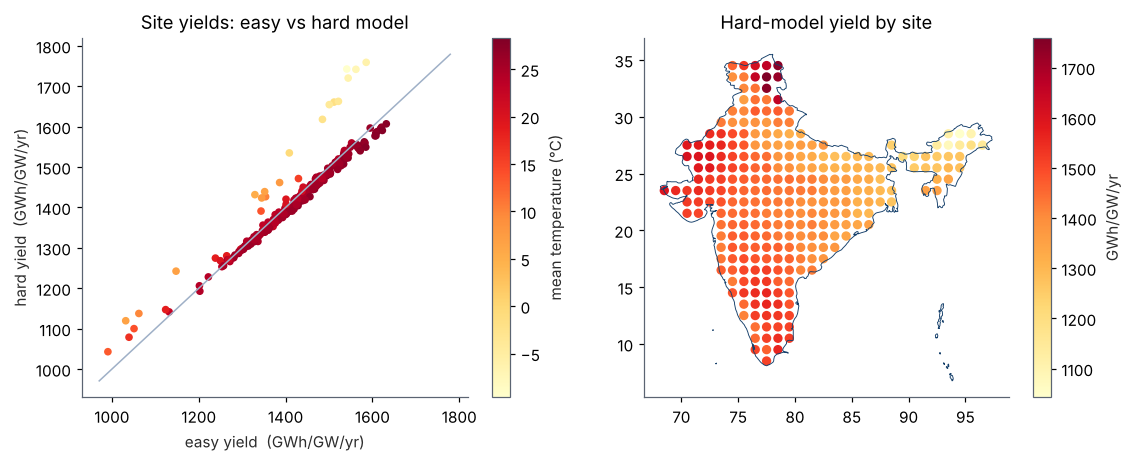

In [3]:
days72 = np.tile(DAYS, 6)[None, :]
G_op   = 1000.0 * GHI / SUN_HOURS
T_cell = TEMP + G_op / (U0 + U1 * WIND)
phi    = 1.0 + GAMMA * (T_cell - 25.0)                 # thermal factor (>1 when it is cold)
E_hard = ETA0 * phi * GHI * days72                      # (n, 72)  GWh per GW per month
PR_easy = E_hard.sum() / (GHI * days72).sum()
E_easy = PR_easy * GHI * days72
ebar_easy, ebar_hard = E_easy.sum(1) / 6, E_hard.sum(1) / 6

print(f"fleet-average PR used by the easy model: {PR_easy:.4f}")
print(f"thermal factor phi: mean {phi.mean():.3f}, min {phi.min():.3f}, max {phi.max():.3f}")
print(f"yield [GWh/GW/yr]  easy: {ebar_easy.min():.0f}-{ebar_easy.max():.0f}   hard: {ebar_hard.min():.0f}-{ebar_hard.max():.0f}")
print(f"rank correlation between the two yield rankings: {pd.Series(ebar_easy).corr(pd.Series(ebar_hard), method='spearman'):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.3))
sc = ax[0].scatter(ebar_easy, ebar_hard, c=TEMP.mean(1), cmap="YlOrRd", s=16)
lim = [ebar_easy.min() - 20, ebar_hard.max() + 20]; ax[0].plot(lim, lim, color=GREY, lw=1)
ax[0].set_xlabel("easy yield  (GWh/GW/yr)"); ax[0].set_ylabel("hard yield  (GWh/GW/yr)")
ax[0].set_title("Site yields: easy vs hard model"); plt.colorbar(sc, ax=ax[0], label="mean temperature (°C)")
sc = ax[1].scatter(sites.LON, sites.LAT, c=ebar_hard, cmap="YlOrRd", s=26); draw_india(ax[1], 0.6)
ax[1].set_aspect("equal"); ax[1].set_title("Hard-model yield by site"); plt.colorbar(sc, ax=ax[1], label="GWh/GW/yr")
plt.tight_layout(); plt.savefig("figures/fig_yield.png", dpi=200); plt.show()

## 4. Easy problem: a linear program
**Variables:** $x_i\ge 0$, the capacity (GW) installed at site $i$.

$$\begin{aligned}
\max_{x}\quad & \sum_{i=1}^{n} \bar e_i^{\text{easy}}\, x_i && \text{(expected annual energy)}\\
\text{s.t.}\quad & c\sum_{i} x_i \le B && \text{(budget)}\\
& 0\le x_i\le U \quad \forall i && \text{(site capacity cap)}
\end{aligned}$$

This is a **fractional knapsack**. Its optimum can be written down: rank sites by yield per rupee (all sites cost the same here, so by $\bar e_i$) and fill each to $U$ until the money runs out. We solve it with an LP solver and also verify it against that closed form. The **dual variable** of the budget constraint, $\lambda^\*$, is the energy gained per extra rupee crore of budget.

In [4]:
def solve_easy(ebar, budget=BUDGET, c0=C0, ucap=UCAP):
    k = len(ebar)
    r = linprog(-ebar, A_ub=c0 * np.ones((1, k)), b_ub=[budget], bounds=[(0, ucap)] * k, method="highs")
    assert r.status == 0
    return r.x, -r.fun, -r.ineqlin.marginals[0]          # x, objective (GWh/yr), budget dual (GWh per Rs crore)

def greedy_easy(ebar, budget=BUDGET, c0=C0, ucap=UCAP):
    x = np.zeros(len(ebar)); left = budget / c0
    for i in np.argsort(-ebar):
        x[i] = min(ucap, left); left -= x[i]
        if left <= 1e-12: break
    return x

x_easy, obj_easy, dual_easy = solve_easy(ebar_easy)
x_greedy = greedy_easy(ebar_easy)
print(f"LP objective              : {obj_easy:,.1f} GWh/yr")
print(f"closed-form greedy        : {ebar_easy @ x_greedy:,.1f} GWh/yr   (max |x_LP - x_greedy| = {np.abs(x_easy - x_greedy).max():.2e})")
print(f"budget dual               : {dual_easy:.4f} GWh per Rs crore  (= marginal yield / cost = {np.sort(ebar_easy)[::-1][int(BUDGET/C0)]/C0:.4f})")
print(f"capacity {x_easy.sum():.2f} GW | sites at the cap {int((x_easy > UCAP-1e-9).sum())} | plants {int((x_easy > 1e-9).sum())}")

LP objective              : 35,295.0 GWh/yr
closed-form greedy        : 35,295.0 GWh/yr   (max |x_LP - x_greedy| = 7.77e-16)
budget dual               : 0.3442 GWh per Rs crore  (= marginal yield / cost = 0.3442)
capacity 22.22 GW | sites at the cap 22 | plants 23


**Why this problem is "easy" and also "wrong".** It treats every GW of capacity at a site as interchangeable and free of overhead. In reality each plant needs a substation and evacuation line (a fixed cost), very small plants are not viable, hot sites lose output, and a portfolio that depends on one region has large swings in monthly generation. The hard problem adds those layers.

## 5. Hard problem: mixed-integer quadratic program (MIQP)
**Variables:** $x_i\ge0$ (GW) and $y_i\in\{0,1\}$ ($y_i=1$ if a plant is built at site $i$).

Let $m_{it}=e^{\text{hard}}_{it}-\frac1{72}\sum_s e^{\text{hard}}_{is}$ be the deviation of site $i$'s output from its own mean month. The portfolio's monthly generation then has variance

$$\operatorname{Var}(x)=\frac1{71}\sum_{t=1}^{72}\Big(\sum_i m_{it}x_i\Big)^2 \;=\; x^\top\Sigma x,\qquad \Sigma=\operatorname{Cov}_t\big(e^{\text{hard}}_{i\cdot},e^{\text{hard}}_{j\cdot}\big).$$

$$\begin{aligned}
\max_{x,y}\quad & \sum_i \bar e_i^{\text{hard}}x_i\;-\;\lambda\,x^\top\Sigma\,x && \text{(energy minus risk penalty)}\\
\text{s.t.}\quad & c\sum_i x_i+F\sum_i y_i\le B && \text{(budget including fixed connection charges)}\\
& L\,y_i\le x_i\le U\,y_i\quad\forall i && \text{(build only if } x_i\ge L\text{; cap } U)\\
& y_i\in\{0,1\}
\end{aligned}$$

**Why this is a MIQP.** The objective has a quadratic term and the siting decisions are binary. Because $\Sigma$ is positive semidefinite the objective is **concave** (a convex problem once the binaries are relaxed), so branch-and-bound can solve it to proven optimality. The feasible set $\{0\}\cup[L,U]$ for each $x_i$ is what makes the hard problem non-convex.

**What each added layer does**
- *Heat and wind de-rating* changes which sites are best (cold, windy, high-GHI sites gain; hot ones lose).
- *Fixed charge $F$ and minimum size $L$* link where to build with how much to build, and make many small plants unattractive.
- *Variance penalty $\lambda$* is the mean-variance idea from portfolio theory applied to sites: months when the whole fleet is weak (monsoon, winter) hurt, so the optimiser prefers sites whose output is high when the others are low. $\lambda=0$ removes the risk term.

**Implementation.** $\Sigma$ is dense ($274\times274$), so we use the 72 months directly: auxiliary variables $z_t=\sum_i m_{it}x_i$ and one quadratic constraint $\sum_t z_t^2\le 71\,s$, with $s$ penalised in the objective. This is the same model, much sparser. We solve it with SCIP (`pyscipopt`).

In [5]:
from pyscipopt import Model, quicksum
import cvxpy as cp

DEV = E_hard - E_hard.mean(axis=1, keepdims=True)       # m_it, shape (n, 72)

def solve_hard(ebar, lam, budget=BUDGET, c0=C0, fixed=FIXED, lmin=LMIN, ucap=UCAP, fix_y=None, time_limit=120, gap=1e-4):
    k = len(ebar); m = Model(); m.hideOutput()
    m.setParam("limits/time", time_limit); m.setParam("limits/gap", gap)
    x = [m.addVar(lb=0, ub=ucap) for _ in range(k)]
    y = [m.addVar(vtype="B") for _ in range(k)]
    z = [m.addVar(lb=-1e6, ub=1e6) for _ in range(72)]
    s = m.addVar(lb=0, ub=1e9)                                   # s >= Var(x)
    m.addCons(quicksum(c0 * x[i] + fixed * y[i] for i in range(k)) <= budget)
    for i in range(k):
        m.addCons(x[i] <= ucap * y[i]); m.addCons(x[i] >= lmin * y[i])
        if fix_y is not None: m.addCons(y[i] == float(fix_y[i]))
    for t in range(72):
        m.addCons(z[t] == quicksum(float(DEV[i, t]) * x[i] for i in range(k)))
    m.addCons(quicksum(z[t] * z[t] for t in range(72)) <= 71.0 * s)
    m.setObjective(quicksum(float(ebar[i]) * x[i] for i in range(k)) - lam * s, "maximize")
    m.optimize()
    if m.getNSols() == 0: return None
    xv = np.array([m.getVal(v) for v in x]); yv = np.round([m.getVal(v) for v in y]); xv = np.where(yv > .5, xv, 0.0)
    var = float(((DEV.T @ xv) ** 2).sum() / 71)
    return dict(x=xv, y=yv, energy=float(ebar @ xv), var=var, obj=float(ebar @ xv - lam * var),
                gap=float(m.getGap()), bound=float(m.getDualbound()))

def metrics(x, ebar=ebar_hard):
    """Evaluate any plan under the realistic (hard) physics."""
    y = x > 1e-9; month_out = E_hard.T @ x
    return dict(energy=float(ebar @ x), capacity=float(x.sum()), plants=int(y.sum()),
                cost=float(C0 * x.sum() + FIXED * y.sum()), std_month=float(np.sqrt(((DEV.T @ x) ** 2).sum() / 71)),
                worst_month_ratio=float(month_out.min() / month_out.mean()), smallest_plant=float(x[y].min()) if y.any() else 0.0)

t0 = time.time()
H = solve_hard(ebar_hard, LAM); x_hard = H["x"]
print(f"MIQP solved in {time.time()-t0:.1f} s | objective {H['obj']:,.1f} | proven bound {H['bound']:,.1f} | gap {H['gap']:.1e}")
print(f"energy {H['energy']:,.0f} GWh/yr | monthly std {np.sqrt(H['var']):,.0f} GWh | plants {int(H['y'].sum())} | capacity {x_hard.sum():.2f} GW")

MIQP solved in 1.0 s | objective 27,708.5 | proven bound 27,709.3 | gap 3.0e-05
energy 30,685 GWh/yr | monthly std 315 GWh | plants 20 | capacity 19.56 GW


### Verification of the hard solution
The brief asks for verification of the optimal solutions. We check four things:
1. **Feasibility**: the budget, size and cap constraints hold on the returned solution.
2. **Optimality certificate**: SCIP's proven upper bound is within the requested gap of the objective.
3. **Independent re-solve of the continuous part**: fix the sites SCIP chose and solve the remaining convex QP with a *different* solver (Clarabel through `cvxpy`). It must reproduce SCIP's capacities and objective.
4. **No improving single swap** (local check): trying to replace one chosen site by one unchosen site, the best plan found by re-solving the QP cannot beat the MIQP objective. This is a sanity check on top of the certificate, not a proof.

In [6]:
# 1. feasibility
y_h = x_hard > 1e-9
TOL = 1e-6                                                   # solver feasibility tolerance (relative)
assert C0 * x_hard.sum() + FIXED * y_h.sum() <= BUDGET * (1 + TOL)
assert x_hard.max() <= UCAP + TOL and (x_hard[y_h] >= LMIN - TOL).all()
print(f"1. feasible: cost {C0 * x_hard.sum() + FIXED * y_h.sum():,.1f} <= {BUDGET:,.0f}; plant sizes in [{x_hard[y_h].min():.3f}, {x_hard.max():.3f}] GW")

# 2. certificate
print(f"2. objective {H['obj']:,.2f}  <=  proven bound {H['bound']:,.2f}   (relative gap {H['gap']:.1e})")

# 3. independent QP re-solve with the support fixed
def qp_on_support(ebar, lam, y):
    idx = np.where(np.asarray(y) > .5)[0]; D = DEV[idx]; xs = cp.Variable(len(idx))
    obj = ebar[idx] @ xs - lam * cp.sum_squares(D.T @ xs) / 71.0
    p = cp.Problem(cp.Maximize(obj), [C0 * cp.sum(xs) + FIXED * len(idx) <= BUDGET, xs >= LMIN, xs <= UCAP]); p.solve(solver=cp.CLARABEL)
    x = np.zeros(len(ebar)); x[idx] = xs.value; return x, float(p.value)
x_qp, obj_qp = qp_on_support(ebar_hard, LAM, H["y"])
print(f"3. Clarabel on the same sites: objective {obj_qp:,.2f} (diff {abs(obj_qp - H['obj']):.2e}), max |dx| = {np.abs(x_qp - x_hard).max():.1e} GW")

# 4. single-swap local check (swap one chosen site for one unchosen site, re-solve the QP)
chosen, rest = np.where(y_h)[0], np.where(~y_h)[0]
top_rest = rest[np.argsort(-ebar_hard[rest])][:25]            # the 25 best-yield unchosen sites
best = -np.inf
for i in chosen:
    for j in top_rest:
        yy = H["y"].copy(); yy[i] = 0; yy[j] = 1
        try: best = max(best, qp_on_support(ebar_hard, LAM, yy)[1])
        except Exception: pass
print(f"4. best single swap found: {best:,.2f}  vs MIQP {H['obj']:,.2f}  -> {'no improving swap' if best <= H['obj'] + 1e-6 else 'IMPROVING SWAP FOUND'}")

1. feasible: cost 100,000.0 <= 100,000; plant sizes in [0.591, 1.000] GW
2. objective 27,708.52  <=  proven bound 27,709.35   (relative gap 3.0e-05)
3. Clarabel on the same sites: objective 27,708.52 (diff 2.55e-04), max |dx| = 3.5e-05 GW


4. best single swap found: 27,707.52  vs MIQP 27,708.52  -> no improving swap


## 6. Easy vs hard: the price of realism
We compare the two plans on equal footing by **evaluating every plan with the realistic (hard) physics**. The easy model's *claimed* energy is also shown, because the gap between what it claims and what a realistic model delivers is itself part of the price of realism.

The step-by-step decomposition separates where the lost energy comes from:

| Step | Plan | What changes |
|---|---|---|
| A | Easy LP, its own claim | baseline |
| B | Same easy plan, realistic yields | heat and wind physics only |
| C | Easy plan's sites, capacities re-optimised | fixed grid-connection charges eat budget; minimum size |
| D | Free re-siting, no risk term ($\lambda=0$) | optimiser may choose different sites |
| E | Full hard MIQP ($\lambda$ as set) | add the monthly-variance penalty |

,objective,energy GWh/yr,capacity GW,plants,cost Rs cr,monthly std GWh,worst month / mean,smallest plant GW
Easy LP plan,28675.030,35242.146,22.222,23.0,113800.000,467.872,0.720,0.222
"Easy sites, resized (C)",25594.551,30501.900,19.156,23.0,100000.000,404.448,0.724,0.200
"Hard, no risk term (D)",24686.254,31864.920,19.556,20.0,100000.000,489.172,0.683,0.556
Hard MIQP (E),27708.524,30684.561,19.556,20.0,100000.001,314.962,0.753,0.591



Easy claimed 35,295 GWh/yr; the same plan really delivers 35,242, but costs 113,800 Rs crore with fixed charges vs a budget of 100,000.
Price of realism (energy): 4,610 GWh/yr = 13.1% of the easy model's claim
Overlap in chosen sites: 7 of 23 easy sites also appear in the hard solution (20 plants)
Value of re-siting under the full objective: hard 27,709 vs easy sites resized 25,946  (+1,762)


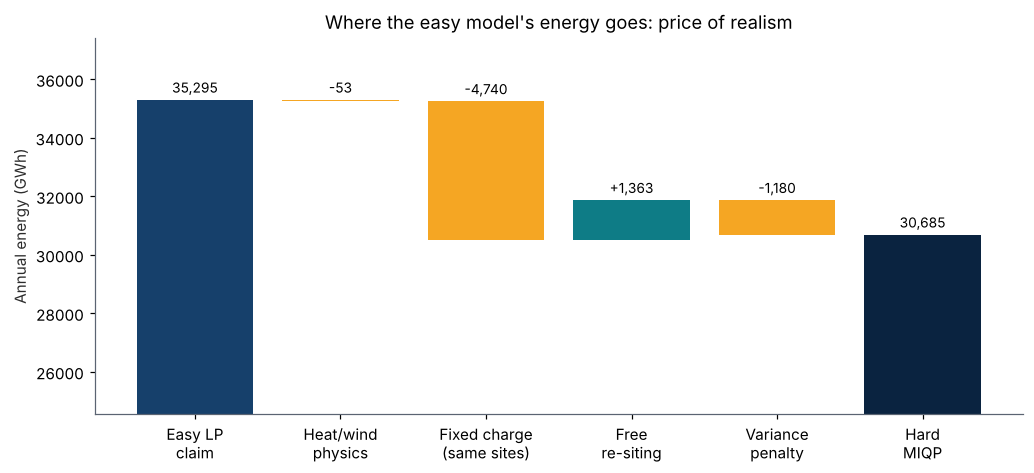

In [7]:
y_easy = (x_easy > 1e-9).astype(float)
S_C = solve_hard(ebar_hard, 0.0, fix_y=y_easy)               # easy's sites, resized under fixed charge, no risk term
S_D = solve_hard(ebar_hard, 0.0)                              # free siting, no risk term
S_F = solve_hard(ebar_hard, LAM, fix_y=y_easy)               # easy's sites, full MIQP objective

steps = {"A  Easy LP (its own claim)": obj_easy,
         "B  Easy plan, realistic yield": float(ebar_hard @ x_easy),
         "C  + fixed charge, same sites": S_C["energy"],
         "D  + free re-siting": S_D["energy"],
         "E  + variance penalty = hard MIQP": H["energy"]}

plans = {"Easy LP plan": x_easy, "Easy sites, resized (C)": S_C["x"], "Hard, no risk term (D)": S_D["x"], "Hard MIQP (E)": x_hard}
tbl = pd.DataFrame({k: metrics(v) for k, v in plans.items()}).T
tbl.insert(0, "objective (energy - lam*var)", [float(ebar_hard @ v - LAM * ((DEV.T @ v) ** 2).sum() / 71) for v in plans.values()])
tbl.columns = ["objective", "energy GWh/yr", "capacity GW", "plants", "cost Rs cr", "monthly std GWh", "worst month / mean", "smallest plant GW"]
display(tbl.round(3))
print(f"\nEasy claimed {obj_easy:,.0f} GWh/yr; the same plan really delivers {ebar_hard @ x_easy:,.0f}, but costs {metrics(x_easy)['cost']:,.0f} Rs crore with fixed charges vs a budget of {BUDGET:,.0f}.")
price = obj_easy - H["energy"]
print(f"Price of realism (energy): {price:,.0f} GWh/yr = {100*price/obj_easy:.1f}% of the easy model's claim")
print(f"Overlap in chosen sites: {int(((x_easy>1e-9)&(x_hard>1e-9)).sum())} of {int((x_easy>1e-9).sum())} easy sites also appear in the hard solution ({int(y_h.sum())} plants)")
print(f"Value of re-siting under the full objective: hard {H['obj']:,.0f} vs easy sites resized {S_F['obj']:,.0f}  (+{H['obj']-S_F['obj']:,.0f})")

# ---- waterfall
vals = list(steps.values()); labels = ["Easy LP\nclaim", "Heat/wind\nphysics", "Fixed charge\n(same sites)", "Free\nre-siting", "Variance\npenalty", "Hard\nMIQP"]
fig, ax = plt.subplots(figsize=(9.5, 4.4)); base = vals[0]
ax.bar(0, vals[0], color=BLUE)
for k in range(1, 5):
    dlt = vals[k] - vals[k - 1]; lo = min(vals[k], vals[k - 1])
    ax.bar(k, abs(dlt), bottom=lo, color=TEAL if dlt > 0 else GOLD)
    ax.text(k, max(vals[k], vals[k - 1]) + 250, f"{dlt:+,.0f}", ha="center", fontsize=9)
ax.bar(5, vals[4], color=NAVY); ax.text(0, vals[0] + 250, f"{vals[0]:,.0f}", ha="center", fontsize=9); ax.text(5, vals[4] + 250, f"{vals[4]:,.0f}", ha="center", fontsize=9)
ax.set_xticks(range(6)); ax.set_xticklabels(labels); ax.set_ylim(vals[4] * 0.8, vals[0] * 1.06); ax.set_ylabel("Annual energy (GWh)")
ax.set_title("Where the easy model's energy goes: price of realism"); plt.tight_layout(); plt.savefig("figures/fig_waterfall.png", dpi=200); plt.show()

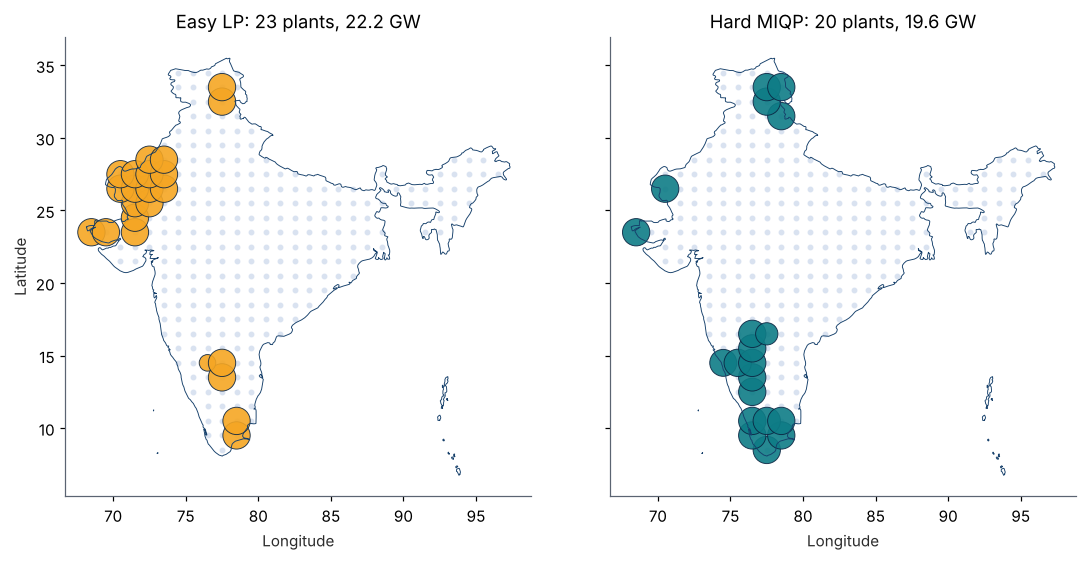

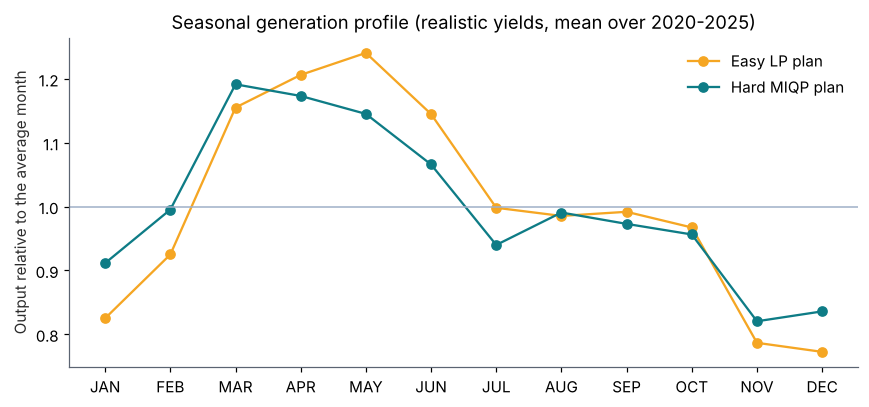

In [8]:
# ---- where the plants are
fig, ax = plt.subplots(1, 2, figsize=(10.5, 5.0), sharey=True)
for a, x, name, col in [(ax[0], x_easy, "Easy LP", GOLD), (ax[1], x_hard, "Hard MIQP", TEAL)]:
    a.scatter(sites.LON, sites.LAT, s=8, c="#D9E2F0"); draw_india(a, 0.6)
    s = x > 1e-9; a.scatter(sites.LON[s], sites.LAT[s], s=60 + 260 * x[s], c=col, edgecolor=NAVY, lw=0.6, alpha=0.9)
    a.set_aspect("equal"); a.set_title(f"{name}: {int(s.sum())} plants, {x.sum():.1f} GW"); a.set_xlabel("Longitude")
ax[0].set_ylabel("Latitude"); plt.tight_layout(); plt.savefig("figures/fig_maps.png", dpi=200); plt.show()

# ---- seasonal profile of each plan under realistic yields
prof = lambda x: (lambda o: o / o.mean())((E_hard.T @ x).reshape(6, 12).mean(0))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(MONTHS, prof(x_easy), "-o", color=GOLD, label="Easy LP plan"); ax.plot(MONTHS, prof(x_hard), "-o", color=TEAL, label="Hard MIQP plan")
ax.axhline(1, color=GREY, lw=1); ax.set_ylabel("Output relative to the average month"); ax.set_title("Seasonal generation profile (realistic yields, mean over 2020-2025)")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig("figures/fig_profile.png", dpi=200); plt.show()

## 7. Sensitivity analysis
Three sweeps show how the hard solution responds to the assumptions we had to make:
- **Budget $B$**: does the gap between easy and hard persist at different scales?
- **Risk aversion $\lambda$**: the energy-versus-volatility frontier, with the easy plan's sites (resized) for comparison.
- **Fixed connection cost $F$**: how strongly the fixed charge drives the answer.

In [9]:
sweeps = {"budget": [], "lambda": [], "fixed": []}
for B in [25_000, 50_000, 75_000, 100_000, 125_000, 150_000]:
    xe, oe, _ = solve_easy(ebar_easy, budget=B); h = solve_hard(ebar_hard, LAM, budget=B)
    sweeps["budget"].append(dict(B=B, easy_claimed=oe, easy_real=float(ebar_hard @ xe), hard=h["energy"], hard_plants=int(h["y"].sum()), hard_cap=float(h["x"].sum()), gap=h["gap"]))
for lam in [0, 0.005, 0.01, 0.02, 0.03, 0.05, 0.1, 0.2]:
    h = solve_hard(ebar_hard, lam); s = solve_hard(ebar_hard, lam, fix_y=y_easy); mh, ms = metrics(h["x"]), metrics(s["x"])
    sweeps["lambda"].append(dict(lam=lam, energy=mh["energy"], std=mh["std_month"], worst=mh["worst_month_ratio"], plants=mh["plants"],
                                 easy_sites_energy=ms["energy"], easy_sites_std=ms["std_month"], gap=h["gap"]))
for F in [0, 300, 600, 900, 1200]:
    h = solve_hard(ebar_hard, LAM, fixed=F)
    sweeps["fixed"].append(dict(F=F, energy=h["energy"], plants=int(h["y"].sum()), cap=float(h["x"].sum()), gap=h["gap"]))
sb, sl, sf = (pd.DataFrame(sweeps[k]) for k in ["budget", "lambda", "fixed"])
display(sb.round(2)); display(sl.round(3)); display(sf.round(2))
print("largest MIP gap over all sweep solves:", max(sb.gap.max(), sl.gap.max(), sf.gap.max()))

Cannot set feasibility tolerance to small value 3.49828e-11 without GMP - using 1e-10.


Cannot set feasibility tolerance to small value 3e-11 without GMP - using 1e-10.
Cannot set feasibility tolerance to small value 3e-11 without GMP - using 1e-10.


,B,easy_claimed,easy_real,hard,hard_plants,hard_cap,gap
0,25000,8998.81,8856.01,8115.53,5,4.89,0.0
1,50000,17868.31,17797.55,15692.09,10,9.78,0.0
2,75000,26623.08,26423.22,23240.97,15,14.67,0.0
3,100000,35294.99,35242.15,30684.56,20,19.56,0.0
4,125000,43872.30,44150.54,37691.75,25,24.44,0.0
5,150000,52409.28,52648.02,44323.30,30,29.33,0.0


,lam,energy,std,worst,plants,easy_sites_energy,easy_sites_std,gap
0,0.000,31864.920,489.172,0.683,20,30501.900,404.448,0.0
1,0.005,31630.791,411.685,0.720,20,30490.335,390.550,0.0
2,0.010,31361.818,369.038,0.743,20,30490.335,390.550,0.0
3,0.020,30991.471,333.596,0.751,20,30472.474,388.454,0.0
4,0.030,30684.561,314.962,0.753,20,30423.772,386.321,0.0
5,0.050,29397.133,260.293,0.792,20,30301.038,381.332,0.0
6,0.100,27486.759,198.615,0.833,20,28325.535,351.622,0.0
7,0.200,26094.590,169.641,0.861,20,16823.586,194.952,0.0


,F,energy,plants,cap,gap
0,0,34704.86,25,22.22,0.0
1,300,32562.21,21,20.82,0.0
2,600,30684.56,20,19.56,0.0
3,900,28966.96,19,18.42,0.0
4,1200,27475.75,18,17.42,0.0


largest MIP gap over all sweep solves: 6.63268649147386e-05


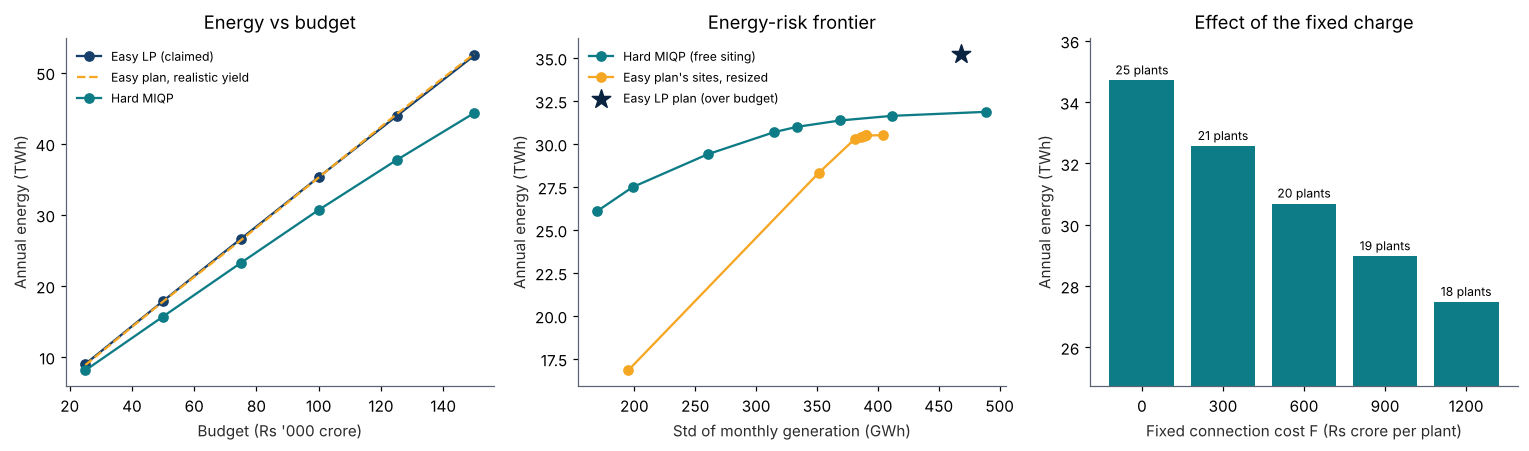

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
a = ax[0]; a.plot(sb.B / 1000, sb.easy_claimed / 1000, "-o", color=BLUE, label="Easy LP (claimed)")
a.plot(sb.B / 1000, sb.easy_real / 1000, "--", color=GOLD, label="Easy plan, realistic yield"); a.plot(sb.B / 1000, sb.hard / 1000, "-o", color=TEAL, label="Hard MIQP")
a.set_xlabel("Budget (Rs '000 crore)"); a.set_ylabel("Annual energy (TWh)"); a.set_title("Energy vs budget"); a.legend(frameon=False, fontsize=8)
a = ax[1]; a.plot(sl["std"], sl.energy / 1000, "-o", color=TEAL, label="Hard MIQP (free siting)")
a.plot(sl.easy_sites_std, sl.easy_sites_energy / 1000, "-o", color=GOLD, label="Easy plan's sites, resized")
pe = metrics(x_easy); a.scatter([pe["std_month"]], [pe["energy"] / 1000], marker="*", s=160, color=NAVY, zorder=5, label="Easy LP plan (over budget)")
a.set_xlabel("Std of monthly generation (GWh)"); a.set_ylabel("Annual energy (TWh)"); a.set_title("Energy-risk frontier"); a.legend(frameon=False, fontsize=8)
a = ax[2]; a.bar(sf.F.astype(str), sf.energy / 1000, color=TEAL); a.set_xlabel("Fixed connection cost F (Rs crore per plant)"); a.set_ylabel("Annual energy (TWh)")
for i, r in sf.iterrows(): a.text(i, r.energy / 1000 + 0.2, f"{int(r.plants)} plants", ha="center", fontsize=8)
a.set_ylim(sf.energy.min() / 1000 * 0.9, sf.energy.max() / 1000 * 1.04); a.set_title("Effect of the fixed charge")
plt.tight_layout(); plt.savefig("figures/fig_sweeps.png", dpi=200); plt.show()

## 8. Additional analysis: regions, seasonality, years, cross-evaluation
Four extra views of the two plans, plus figures used in the slides.

- **Regional mix.** Sites are grouped with simple latitude-longitude boxes (not state borders): *Rajasthan-Gujarat* (lon <= 74, 22-29 N), *Himalayan north* (lat >= 30), *South* (lat <= 17), *Other*.
- **Cross-evaluation.** Each plan is scored with both models. This shows what you would believe if you trusted the easy model, and what you would actually get.
- **Year-by-year robustness.** The six years of data are kept separate, so we can see how much each plan's annual energy moves from year to year.
- **Monthly series.** The 72-month output of each plan, which is what the variance penalty acts on.

,Easy LP,Hard MIQP
region,,
Rajasthan-Gujarat,16.00,2.00
Himalayan north,2.00,4.00
South,4.22,13.56
Other,0.00,0.00


,Easy LP,Hard MIQP
region,,
Rajasthan-Gujarat,16,2
Himalayan north,2,4
South,5,14
Other,0,0


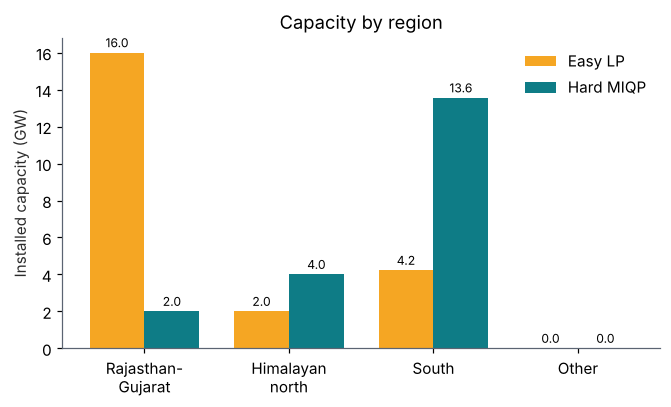

In [11]:
# ---- regional mix
def region(lat, lon):
    if lat >= 30: return "Himalayan north"
    if lat <= 17: return "South"
    if lon <= 74 and 22 <= lat <= 29: return "Rajasthan-Gujarat"
    return "Other"
sites["region"] = [region(a, b) for a, b in zip(sites.LAT, sites.LON)]
ORDER = ["Rajasthan-Gujarat", "Himalayan north", "South", "Other"]
reg_gw = pd.DataFrame({"Easy LP": pd.Series(x_easy).groupby(sites.region).sum(), "Hard MIQP": pd.Series(x_hard).groupby(sites.region).sum()}).reindex(ORDER).fillna(0)
reg_n = pd.DataFrame({"Easy LP": pd.Series(x_easy > 1e-9).groupby(sites.region).sum(), "Hard MIQP": pd.Series(x_hard > 1e-9).groupby(sites.region).sum()}).reindex(ORDER).fillna(0).astype(int)
display(reg_gw.round(2)); display(reg_n)

fig, ax = plt.subplots(figsize=(6.2, 3.8)); w = 0.38; xs = np.arange(len(ORDER))
ax.bar(xs - w / 2, reg_gw["Easy LP"], w, color=GOLD, label="Easy LP"); ax.bar(xs + w / 2, reg_gw["Hard MIQP"], w, color=TEAL, label="Hard MIQP")
for i, r in enumerate(ORDER):
    ax.text(i - w / 2, reg_gw.loc[r, "Easy LP"] + 0.3, f"{reg_gw.loc[r,'Easy LP']:.1f}", ha="center", fontsize=8)
    ax.text(i + w / 2, reg_gw.loc[r, "Hard MIQP"] + 0.3, f"{reg_gw.loc[r,'Hard MIQP']:.1f}", ha="center", fontsize=8)
ax.set_xticks(xs); ax.set_xticklabels([o.replace("-", "-\n") if o == "Rajasthan-Gujarat" else o.replace(" ", "\n") for o in ORDER]); ax.set_ylabel("Installed capacity (GW)")
ax.set_title("Capacity by region"); ax.legend(frameon=False); plt.tight_layout(); plt.savefig("figures/fig_regions.png", dpi=200); plt.show()

In [12]:
# ---- cross-evaluation: score each plan with both models
cross = {}
for name, x in [("Easy LP plan", x_easy), ("Hard MIQP plan", x_hard)]:
    cost_hard = float(C0 * x.sum() + FIXED * (x > 1e-9).sum())
    cross[name] = dict(easy_view_energy=float(ebar_easy @ x), hard_view_energy=float(ebar_hard @ x), cost_easy_view=float(C0 * x.sum()),
                       cost_hard_view=cost_hard, within_budget_hard=bool(cost_hard <= BUDGET * (1 + 1e-6)),
                       std_month=float(np.sqrt(((DEV.T @ x) ** 2).sum() / 71)))
display(pd.DataFrame(cross).T.round(1))
repaired = dict(energy=S_C["energy"], std=metrics(S_C["x"])["std_month"])
print(f"Easy plan repaired to the budget (same sites, resized): {repaired['energy']:,.0f} GWh/yr, std {repaired['std']:,.0f}")
print(f"Hard plan: {H['energy']:,.0f} GWh/yr, std {np.sqrt(H['var']):,.0f}  -> hard beats the repaired easy plan on energy by {H['energy']-repaired['energy']:,.0f} GWh and on volatility by {repaired['std']-np.sqrt(H['var']):,.0f} GWh")

,easy_view_energy,hard_view_energy,cost_easy_view,cost_hard_view,within_budget_hard,std_month
Easy LP plan,35294.986773,35242.145982,100000.0,113800.0,False,467.871647
Hard MIQP plan,30171.336394,30684.56133,88000.00088,100000.00088,True,314.962306


Easy plan repaired to the budget (same sites, resized): 30,502 GWh/yr, std 404
Hard plan: 30,685 GWh/yr, std 315  -> hard beats the repaired easy plan on energy by 183 GWh and on volatility by 89 GWh


,Easy LP plan,"Easy sites, resized",Hard MIQP plan
2020,35974.0,31148.0,31119.0
2021,35447.0,30666.0,30488.0
2022,35582.0,30794.0,30528.0
2023,35274.0,30519.0,31419.0
2024,34536.0,29913.0,30400.0
2025,34640.0,29971.0,30154.0


coefficient of variation across years (%): {'Easy LP plan': 1.58, 'Easy sites, resized': 1.58, 'Hard MIQP plan': 1.57}
worst year vs the plan's own mean (%): {'Easy LP plan': -2.0, 'Easy sites, resized': -1.93, 'Hard MIQP plan': -1.73}


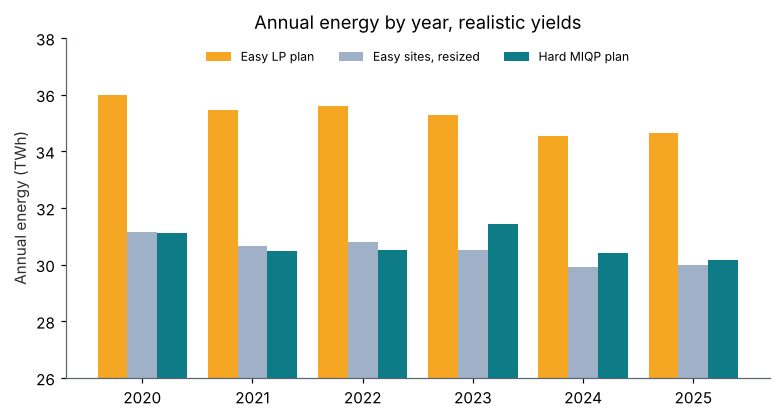

In [13]:
# ---- year-by-year robustness (realistic yields, each calendar year separately)
YEARS = list(range(2020, 2026))
yearly = {nm: (E_hard.T @ x).reshape(6, 12).sum(axis=1) for nm, x in
          [("Easy LP plan", x_easy), ("Easy sites, resized", S_C["x"]), ("Hard MIQP plan", x_hard)]}
ytab = pd.DataFrame(yearly, index=YEARS); display(ytab.round(0))
cv_years = {k: float(100 * v.std(ddof=1) / v.mean()) for k, v in yearly.items()}
worst_year = {k: float(100 * (v.min() / v.mean() - 1)) for k, v in yearly.items()}
print("coefficient of variation across years (%):", {k: round(v, 2) for k, v in cv_years.items()})
print("worst year vs the plan's own mean (%):", {k: round(v, 2) for k, v in worst_year.items()})

fig, ax = plt.subplots(figsize=(7.2, 3.9)); w = 0.27
for k, (nm, col) in enumerate([("Easy LP plan", GOLD), ("Easy sites, resized", GREY), ("Hard MIQP plan", TEAL)]):
    ax.bar(np.arange(6) + (k - 1) * w, ytab[nm] / 1000, w, color=col, label=nm)
ax.set_xticks(range(6)); ax.set_xticklabels(YEARS); ax.set_ylabel("Annual energy (TWh)"); ax.set_ylim(26, 38)
ax.set_title("Annual energy by year, realistic yields"); ax.legend(frameon=False, ncol=3, fontsize=8, loc="upper center"); plt.tight_layout(); plt.savefig("figures/fig_years.png", dpi=200); plt.show()

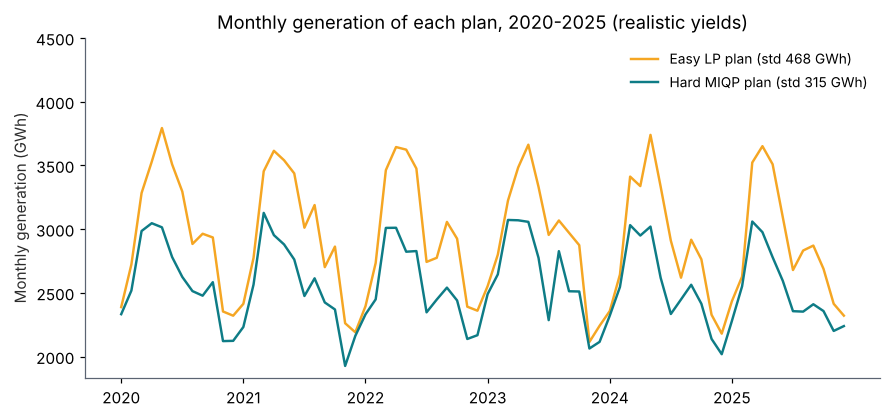

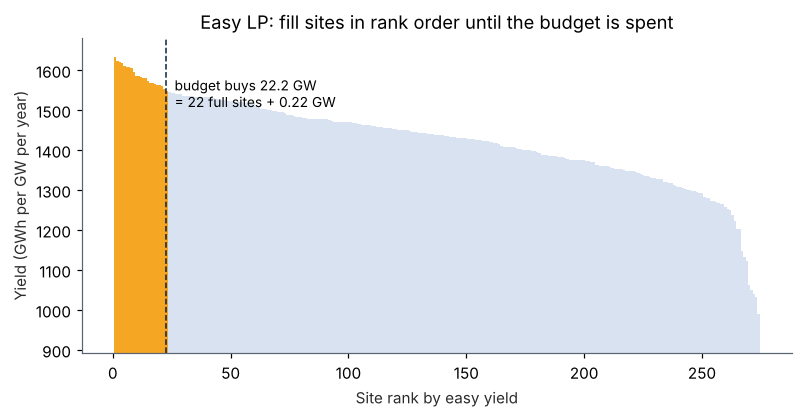

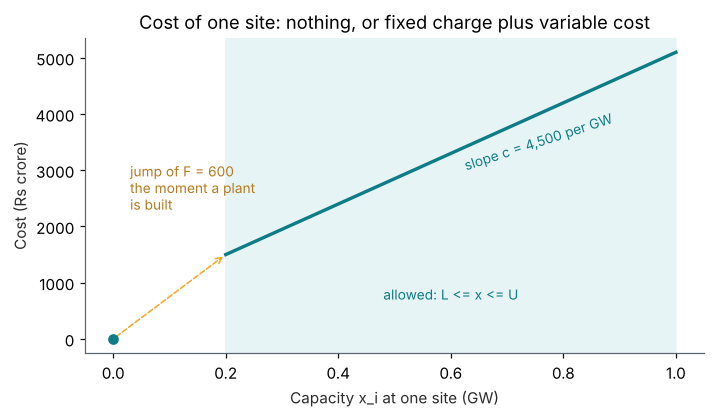

In [14]:
# ---- 72-month series of each plan
t_idx = np.arange(72)
fig, ax = plt.subplots(figsize=(8.2, 3.9))
ax.plot(t_idx, (E_hard.T @ x_easy) , color=GOLD, lw=1.6, label=f"Easy LP plan (std {metrics(x_easy)['std_month']:.0f} GWh)")
ax.plot(t_idx, (E_hard.T @ x_hard), color=TEAL, lw=1.6, label=f"Hard MIQP plan (std {np.sqrt(H['var']):.0f} GWh)")
ax.set_xticks(range(0, 72, 12)); ax.set_xticklabels(YEARS); ax.set_ylabel("Monthly generation (GWh)"); ax.set_title("Monthly generation of each plan, 2020-2025 (realistic yields)")
ax.set_ylim(top=4500); ax.legend(frameon=False, fontsize=9, loc="upper right", ncol=1); plt.tight_layout(); plt.savefig("figures/fig_monthly_series.png", dpi=200); plt.show()

# ---- sorted easy yields and the budget cut
order = np.argsort(-ebar_easy); k_cut = BUDGET / C0
fig, ax = plt.subplots(figsize=(7.4, 3.9))
colors = [GOLD if r < int(np.ceil(k_cut)) else "#D9E2F0" for r in range(n)]
ax.bar(range(1, n + 1), ebar_easy[order], width=1.0, color=colors)
ax.axvline(k_cut + 0.5, color=NAVY, lw=1, ls="--"); ax.text(k_cut + 4, ebar_easy.max() * 0.97, f"budget buys {k_cut:.1f} GW\n= 22 full sites + 0.22 GW", fontsize=9, va="top")
ax.set_xlabel("Site rank by easy yield"); ax.set_ylabel("Yield (GWh per GW per year)"); ax.set_ylim(ebar_easy.min() * 0.9, ebar_easy.max() * 1.03)
ax.set_title("Easy LP: fill sites in rank order until the budget is spent"); plt.tight_layout(); plt.savefig("figures/fig_sorted_yield.png", dpi=200); plt.show()

# ---- fixed charge and the {0} U [L, U] feasible set
fig, ax = plt.subplots(figsize=(6.6, 3.9))
xx = np.linspace(LMIN, UCAP, 50); ax.plot(xx, FIXED + C0 * xx, color=TEAL, lw=2.2); ax.scatter([0], [0], color=TEAL, zorder=5)
ax.plot([0, 0], [0, FIXED + C0 * LMIN], color=GOLD, lw=0, marker="")
ax.annotate("", xy=(LMIN, FIXED + C0 * LMIN), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=GOLD, ls="--"))
ax.axvspan(LMIN, UCAP, color="#E6F4F5", zorder=0); ax.text((LMIN + UCAP) / 2, 700, "allowed: L <= x <= U", ha="center", fontsize=9, color=TEAL)
ax.text(0.03, 2300, f"jump of F = {FIXED:,.0f}\nthe moment a plant\nis built", fontsize=9, color="#B7791F"); ax.text(0.62, 3000, f"slope c = {C0:,.0f} per GW", fontsize=9, color=TEAL, rotation=18)
ax.set_xlabel("Capacity x_i at one site (GW)"); ax.set_ylabel("Cost (Rs crore)"); ax.set_title("Cost of one site: nothing, or fixed charge plus variable cost")
plt.tight_layout(); plt.savefig("figures/fig_fixed_charge.png", dpi=200); plt.show()

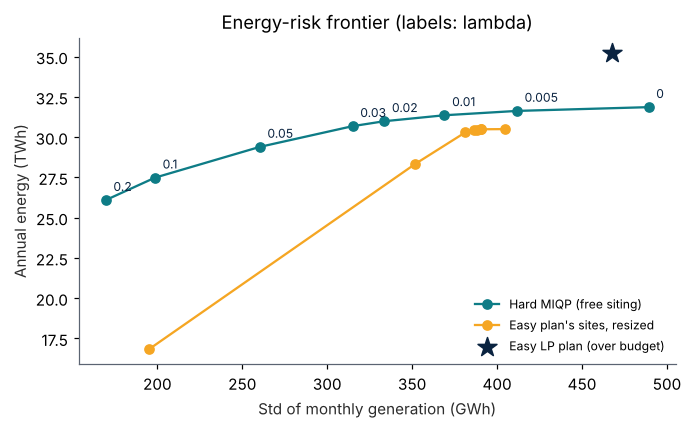

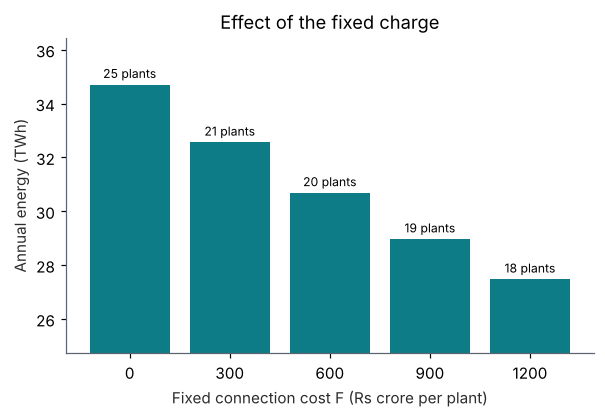

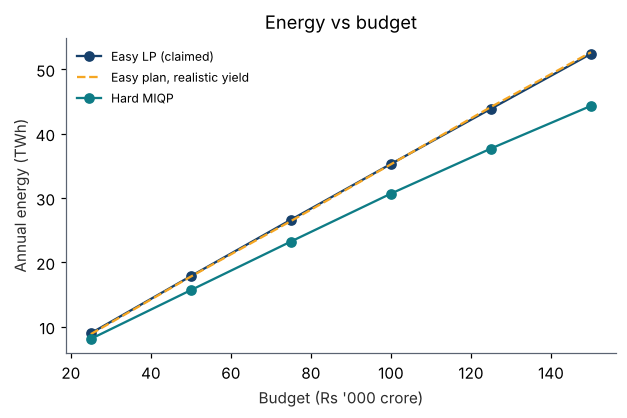

In [15]:
# ---- separate sweep figures for the slides
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.plot(sl["std"], sl.energy / 1000, "-o", color=TEAL, label="Hard MIQP (free siting)")
for _, r in sl.iterrows(): ax.annotate(f"{r.lam:g}", (r["std"], r.energy / 1000), textcoords="offset points", xytext=(5, 6), fontsize=8, color=NAVY)
ax.plot(sl.easy_sites_std, sl.easy_sites_energy / 1000, "-o", color=GOLD, label="Easy plan's sites, resized")
pe = metrics(x_easy); ax.scatter([pe["std_month"]], [pe["energy"] / 1000], marker="*", s=170, color=NAVY, zorder=5, label="Easy LP plan (over budget)")
ax.set_xlabel("Std of monthly generation (GWh)"); ax.set_ylabel("Annual energy (TWh)"); ax.set_title("Energy-risk frontier (labels: lambda)"); ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig("figures/fig_lambda.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(5.6, 3.9)); ax.bar(sf.F.astype(str), sf.energy / 1000, color=TEAL)
for i, r in sf.iterrows(): ax.text(i, r.energy / 1000 + 0.25, f"{int(r.plants)} plants", ha="center", fontsize=8)
ax.set_ylim(sf.energy.min() / 1000 * 0.9, sf.energy.max() / 1000 * 1.05); ax.set_xlabel("Fixed connection cost F (Rs crore per plant)"); ax.set_ylabel("Annual energy (TWh)"); ax.set_title("Effect of the fixed charge")
plt.tight_layout(); plt.savefig("figures/fig_fixed.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(5.8, 3.9))
ax.plot(sb.B / 1000, sb.easy_claimed / 1000, "-o", color=BLUE, label="Easy LP (claimed)"); ax.plot(sb.B / 1000, sb.easy_real / 1000, "--", color=GOLD, label="Easy plan, realistic yield")
ax.plot(sb.B / 1000, sb.hard / 1000, "-o", color=TEAL, label="Hard MIQP"); ax.set_xlabel("Budget (Rs '000 crore)"); ax.set_ylabel("Annual energy (TWh)"); ax.set_title("Energy vs budget"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig("figures/fig_budget.png", dpi=200); plt.show()

X = dict(regions_gw=reg_gw.to_dict(), regions_n=reg_n.to_dict(), cross=cross, repaired_easy=repaired, years={k: v.tolist() for k, v in yearly.items()},
         cv_years=cv_years, worst_year=worst_year)

## 9. Summary and caveats
The cell below prints the headline numbers (so they always match the run) and saves `results.json` and the figures used in the slides.

**How to read the findings**
- *Price of realism.* Compare the easy model's claim with what the hard model can actually deliver. The decomposition shows which layer costs the most, and the three-way table shows whether the easy plan is even feasible once fixed charges are charged.
- *Siting changes.* The hard model picks different sites than the easy one. The overlap count and the maps show how much.
- *Trade-off.* The frontier shows how much annual energy is given up for each reduction in monthly volatility.

**Caveats (say these in the presentation)**
- Capex, fixed charge, minimum size, per-site cap and the risk aversion $\lambda$ are assumptions. Section 7 tests them, but the absolute numbers depend on them.
- Cells are 1°x1° (~110 km) monthly means, so day-to-day variability, curtailment and the real grid layout are not modelled. Each cell is treated as one site.
- The India filter uses cell centres and a 50 m border polygon, so a few coastal or border cells may be on the wrong side.
- All plants are assumed to be fixed-tilt-like with a single efficiency; DNI and DHI are not used because the thermal model needs only GHI, temperature and wind.
- The variance penalty uses 72 monthly observations per site (6 years). It is a historical estimate, not a forecast.

In [16]:
R = dict(
    n_candidate_sites=n, pr_easy=float(PR_easy),
    assumptions=dict(ETA0=ETA0, GAMMA=GAMMA, C0=C0, BUDGET=BUDGET, UCAP=UCAP, FIXED=FIXED, LMIN=LMIN, LAM=LAM, SUN_HOURS=SUN_HOURS),
    easy=dict(claimed=obj_easy, realistic=metrics(x_easy), dual=dual_easy, greedy_matches=bool(np.abs(x_easy - x_greedy).max() < 1e-6)),
    hard=dict(obj=H["obj"], gap=H["gap"], bound=H["bound"], metrics=metrics(x_hard), qp_check_diff=abs(obj_qp - H["obj"])),
    steps=steps, plans={k: metrics(v) for k, v in plans.items()},
    price_of_realism=dict(abs=price, pct=100 * price / obj_easy, value_of_resiting=H["obj"] - S_F["obj"]),
    overlap=dict(easy=int((x_easy > 1e-9).sum()), hard=int(y_h.sum()), common=int(((x_easy > 1e-9) & (x_hard > 1e-9)).sum())),
    profile=dict(easy=prof(x_easy).tolist(), hard=prof(x_hard).tolist()), sweeps=sweeps, extra=X)
json.dump(R, open("results.json", "w"), indent=1, default=float)
out = sites.copy(); out["easy_GWh_per_GW"] = ebar_easy; out["hard_GWh_per_GW"] = ebar_hard; out["mean_thermal_factor"] = phi.mean(1)
out["x_easy_GW"] = x_easy; out["x_hard_GW"] = x_hard; out.to_csv("site_results.csv", index=False)

print("=== HEADLINE NUMBERS ===")
print(f"Candidate sites in India          : {n} (of 960 cells in the file)")
print(f"Easy LP claim                     : {obj_easy:,.0f} GWh/yr, {int((x_easy>1e-9).sum())} plants, {x_easy.sum():.1f} GW")
print(f"  same plan, realistic yield      : {ebar_hard @ x_easy:,.0f} GWh/yr  (cost with fixed charges {metrics(x_easy)['cost']:,.0f} > budget {BUDGET:,.0f})")
print(f"Hard MIQP                         : {H['energy']:,.0f} GWh/yr, {int(y_h.sum())} plants, {x_hard.sum():.1f} GW, monthly std {np.sqrt(H['var']):,.0f} GWh (easy plan: {metrics(x_easy)['std_month']:,.0f})")
print(f"Price of realism                  : {price:,.0f} GWh/yr ({100*price/obj_easy:.1f}% of the easy claim)")
print("files written: results.json, site_results.csv, figures/*.png")

=== HEADLINE NUMBERS ===
Candidate sites in India          : 274 (of 960 cells in the file)
Easy LP claim                     : 35,295 GWh/yr, 23 plants, 22.2 GW
  same plan, realistic yield      : 35,242 GWh/yr  (cost with fixed charges 113,800 > budget 100,000)
Hard MIQP                         : 30,685 GWh/yr, 20 plants, 19.6 GW, monthly std 315 GWh (easy plan: 468)
Price of realism                  : 4,610 GWh/yr (13.1% of the easy claim)
files written: results.json, site_results.csv, figures/*.png
